In [2]:
import pandas as pd

df = pd.read_csv('titanic.csv')
print('rows and cols : ',df.shape)
df.head()

rows and cols :  (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### What the columns mean

- `Survived` — **our target**: `1` = survived, `0` = did not
- `Pclass` — ticket class (1 = 1st, 2 = 2nd, 3 = 3rd) — a proxy for wealth
- `Sex`, `Age` — passenger sex and age
- `SibSp` — number of siblings / spouses aboard
- `Parch` — number of parents / children aboard
- `Fare` — ticket fare paid
- `Embarked` — port boarded (C = Cherbourg, Q = Queenstown, S = Southampton)
- `PassengerId`, `Name`, `Ticket`, `Cabin` — identifiers / mostly-missing columns we'll drop

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [9]:
df = df.drop(columns=['PassengerId','Name','Ticket','Cabin'])

df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

df = pd.get_dummies(df, columns=['Sex','Embarked'], drop_first=True,)

print(df.isnull().sum().sum())
df.head()

0


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


In [14]:
from sklearn.model_selection import train_test_split

X = df.drop('Survived', axis='columns')
y = df.Survived

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Training rows:',X_train.shape[0], 'Testing rows:',X_test.shape[0])

Training rows: 712 Testing rows: 179


## Single Decision Tree

In [21]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train,y_train)

print(f"Decision Tree Traing Accuracy: {round(tree.score(X_train, y_train),3)}")
print(f"Decision Tree Testing Accuracy: {round(tree.score(X_test, y_test),3)}")
print(classification_report(y_test, tree.predict(X_test), target_names=['died','survived']))

Decision Tree Traing Accuracy: 0.982
Decision Tree Testing Accuracy: 0.821
              precision    recall  f1-score   support

        died       0.84      0.88      0.86       110
    survived       0.79      0.72      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.81       179
weighted avg       0.82      0.82      0.82       179



## Random Forest

In [25]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)

print(f"Random Forest Traing Accuracy: {round(forest.score(X_train, y_train),3)}")
print(f"Random Foerst Testing Accuracy: {round(forest.score(X_test, y_test),3)}")
print(classification_report(y_test, forest.predict(X_test), target_names=['died','survived']))

Random Forest Traing Accuracy: 0.982
Random Foerst Testing Accuracy: 0.816
              precision    recall  f1-score   support

        died       0.83      0.87      0.85       110
    survived       0.78      0.72      0.75        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



In [28]:
for n in [10,100]:
    rf = RandomForestClassifier(random_state=42, n_estimators=n)
    rf.fit(X_train, y_train)
    print(f'{n:>3} trees  ->  test accuracy = {rf.score(X_test, y_test):.3f}')

 10 trees  ->  test accuracy = 0.816
100 trees  ->  test accuracy = 0.816


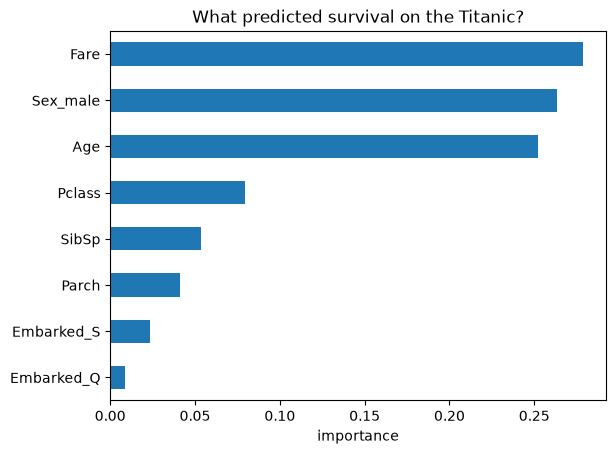

In [33]:
import matplotlib.pyplot as plt

importances = pd.Series(forest.feature_importances_, index=X.columns).sort_values()

importances.plot(kind='barh')
plt.xlabel('importance')
plt.title('What predicted survival on the Titanic?')
plt.show()